# Assignment 1

## Extract webpage data given the url

Create a Python script that performs basic web scraping on a page to extract all the information into text and returns it as a string. String should not contain tags.

In [4]:
import requests
from bs4 import BeautifulSoup


def parse_web_page(url):
    """
    Fetch the content of the given web page.

    Args:
        url (str): The URL of the web page to fetch.

    Returns:
        str: The content of the page as a string.

    Raises:
        HTTPError: If the HTTP request returned an unsuccessful status code.
    """

    headers = {
        "User-Agent": "Mozilla/5.0"
    }

    response = requests.get(url, headers=headers)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    return soup.get_text(separator=" ", strip=True)


print(parse_web_page("https://fmi.chnu.edu.ua/")[:255])
print(parse_web_page("https://en.wikipedia.org/wiki/Web_scraping")[:255])

Головна - Факультет математики та інформатики Перейти до основного вмісту clg-math@chnu.edu.ua 58012, Україна, м. Чернівці, вул. Університетська, 28 Новини Всі Загальні Оголошення Події Студенту Викладачу Вітання Діяльність Наукова Конференції Семінари Ас
Web scraping - Wikipedia Jump to content Main menu Main menu move to sidebar hide Navigation Main page Contents Current events Random article About Wikipedia Contact us Contribute Help Learn to edit Community portal Recent changes Upload file Special page


## Get data from the API

Create a python script that performs basic request to API endpoint and saves that data to a JSON file result.json.

In [5]:
import requests
import json


def parse_api(api_url):
    """
    Fetch the data of the given API endpoint and save it to result.json.

    Args:
        api_url (str): The URL of the API endpoint.

    Returns:
        None.

    Raises:
        HTTPError: If the HTTP request returned an unsuccessful status code.
    """

    response = requests.get(api_url)
    response.raise_for_status()

    data = response.json()

    with open("result.json", "w", encoding="utf-8") as file:
        json.dump(data, file, ensure_ascii=False, indent=4)


parse_api("https://api.github.com/")

## Parse the json file

Parse the `weather.json` file and return weather data for a specific date, that is given as a parameter. Return the data as an array.

In [13]:
import json


def parse_json(date):
    """
    Parse the data from weather.json file and return weather data for a given date.

    Args:
        date (str): The date for which we look up the weather.

    Returns:
        list: a list of weather data for a given date.
    """

    with open("resources/weather.json", "r", encoding="utf-8") as file:
        data = json.load(file)

    result = []

    for item in data["daily"]:
        if item["date"] == date:
            result.append(item)

    return result


target_date = "2024-08-19"
print(parse_json(target_date))

[{'date': '2024-08-19', 'max_temperature': 30.0, 'min_temperature': 21.0, 'precipitation': 5.0, 'wind_speed': 10.0, 'humidity': 70, 'weather_description': 'Light rain'}]


## Parse the csv file

Parse the `weather.csv` file and return weather data for a specific date, that is given as a parameter. Return the data as an array.

In [15]:
import pandas as pd


def parse_csv(date):
    """
    Parse the data from weather.csv file and return weather data for a given date.

    Args:
        date (str): The date for which we look up the weather.

    Returns:
        list: a list of weather data for a given date.
    """

    df = pd.read_csv("resources/weather.csv")

    result = df[df["CET"] == date]

    return result.values.tolist()


target_date = "1997-5-22"
print(parse_csv(target_date))

[['1997-5-22', 25.0, 18.0, 10.0, 11.0, 8.0, 6.0, 88.0, 54.0, 34.0, 1017, 1015, 1012, 10.0, 10.0, 10.0, 11, 3, nan, 0.0, 3.0, nan, 277]]


## Visualize data

Visualize the weather.csv data using matplotlib. Choose your own approach to data visualization. Save the results (as .png, .webp files etc., your choise) in this repository.

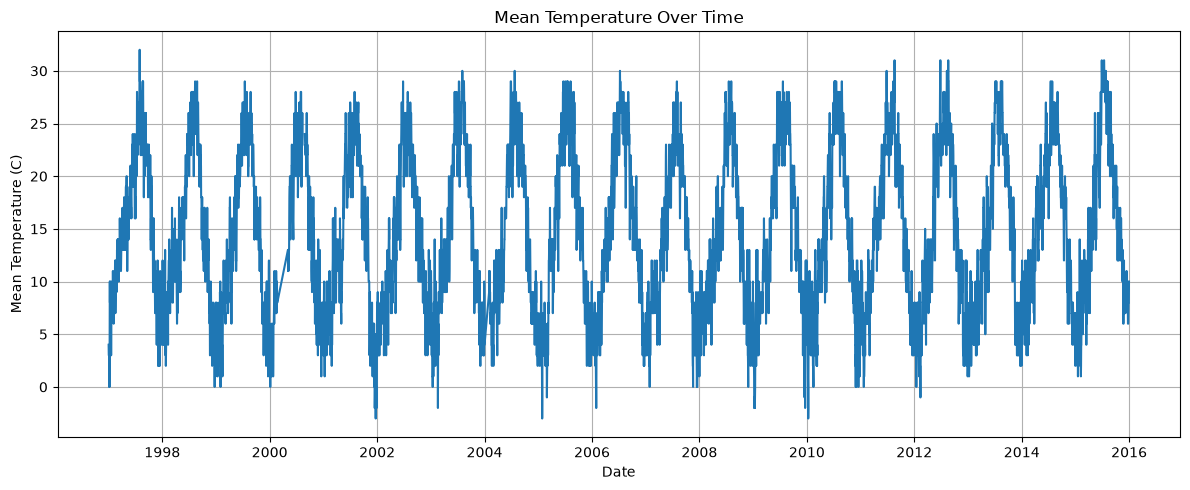

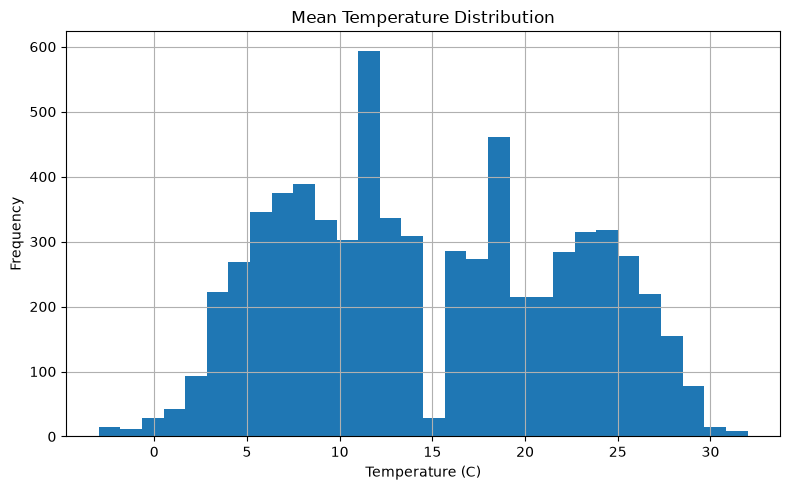

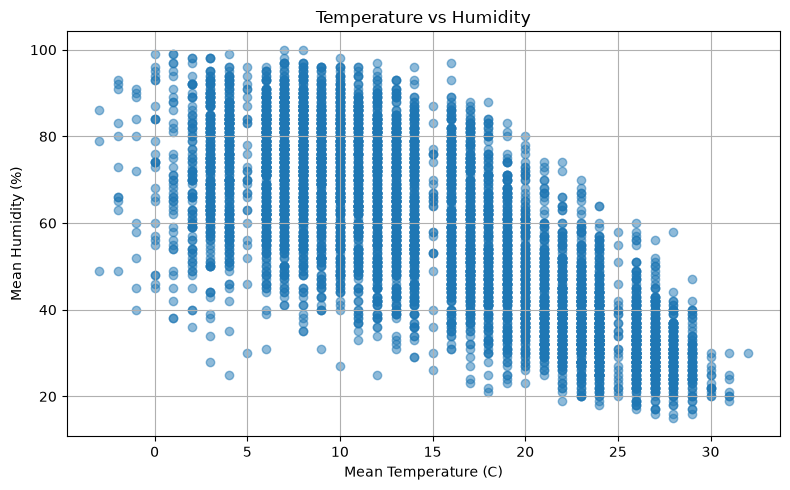

In [18]:
import pandas as pd
import matplotlib.pyplot as plt


def visualize_data():
    """
    Parse the data from weather.csv file and visualize it using Matplotlib.
    Use more than one visualization.
    Save the results in the repository.

    Args:
        None

    Returns:
        None
    """

    # Read CSV file
    df = pd.read_csv("resources/weather.csv")

    # Remove extra spaces from column names
    df.columns = df.columns.str.strip()

    # Convert date column to datetime
    df["CET"] = pd.to_datetime(df["CET"])

    # -----------------------------
    # 1. Mean temperature over time
    # -----------------------------
    plt.figure(figsize=(12, 5))

    plt.plot(
        df["CET"],
        df["Mean TemperatureC"]
    )

    plt.title("Mean Temperature Over Time")
    plt.xlabel("Date")
    plt.ylabel("Mean Temperature (C)")
    plt.grid()

    plt.tight_layout()
    plt.savefig("temperature_over_time.png")
    plt.show()
    plt.close()

    # -----------------------------
    # 2. Temperature histogram
    # -----------------------------
    plt.figure(figsize=(8, 5))

    plt.hist(
        df["Mean TemperatureC"].dropna(),
        bins=30
    )

    plt.title("Mean Temperature Distribution")
    plt.xlabel("Temperature (C)")
    plt.ylabel("Frequency")
    plt.grid()

    plt.tight_layout()
    plt.savefig("temperature_histogram.png")
    plt.show()
    plt.close()

    # -----------------------------
    # 3. Temperature vs Humidity
    # -----------------------------
    plt.figure(figsize=(8, 5))

    plt.scatter(
        df["Mean TemperatureC"],
        df["Mean Humidity"],
        alpha=0.5
    )

    plt.title("Temperature vs Humidity")
    plt.xlabel("Mean Temperature (C)")
    plt.ylabel("Mean Humidity (%)")
    plt.grid()

    plt.tight_layout()
    plt.savefig("temperature_vs_humidity.png")
    plt.show()
    plt.close()


visualize_data()

## Data imputation and normalization.

Download kaggle dataset with incomplete/missing data, and try data imputation techniques (mean, median, mode, knn) on that data. Normalize the data with best option for each dataset (minmax, z-score, robust). Visualize the data (choose your own approach to data visualization).

Dataset options:
- Different Types of Missing Data (by Suryaprabha19) https://www.kaggle.com/datasets/suryaprabha19/different-types-of-missing-data
- Retail Product Dataset with Missing Values (by Himel Sarder) https://www.kaggle.com/datasets/himelsarder/retail-product-dataset-with-missing-values
- Data Cleaning - Feature Imputation (by 
Mr.Machine) https://www.kaggle.com/datasets/ilayaraja07/data-cleaning-feature-imputation
- BI intro to data cleaning eda and machine learning (by Walekhwa Tambiti Leo Philip) https://www.kaggle.com/datasets/walekhwatlphilip/intro-to-data-cleaning-eda-and-machine-learning

Missing values before imputation:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Missing values after creating numeric NaN:
gender                          0
race/ethnicity                  0
parental level of education     0
lunch                           0
test preparation course         0
math score                     10
reading score                  10
writing score                  10
dtype: int64

Missing values after imputation:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64
   gender race/ethnicity parental level of educat

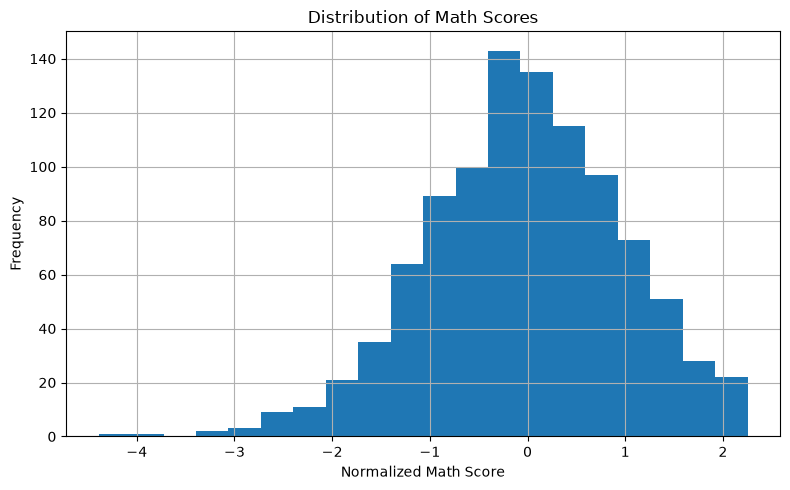

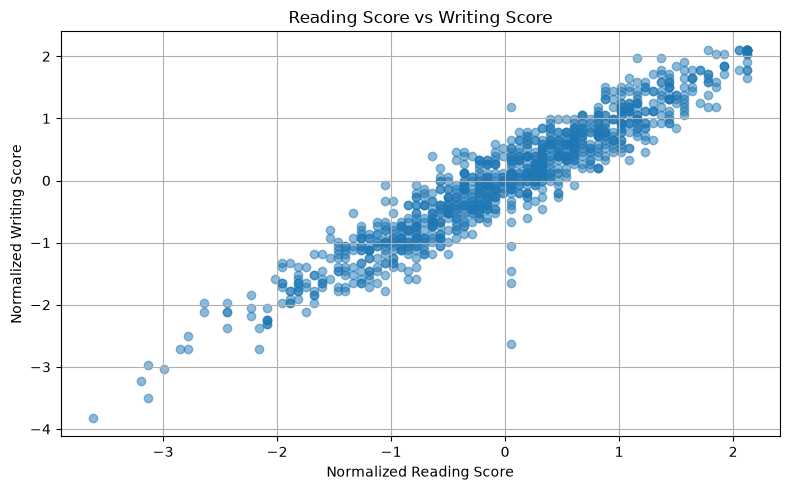

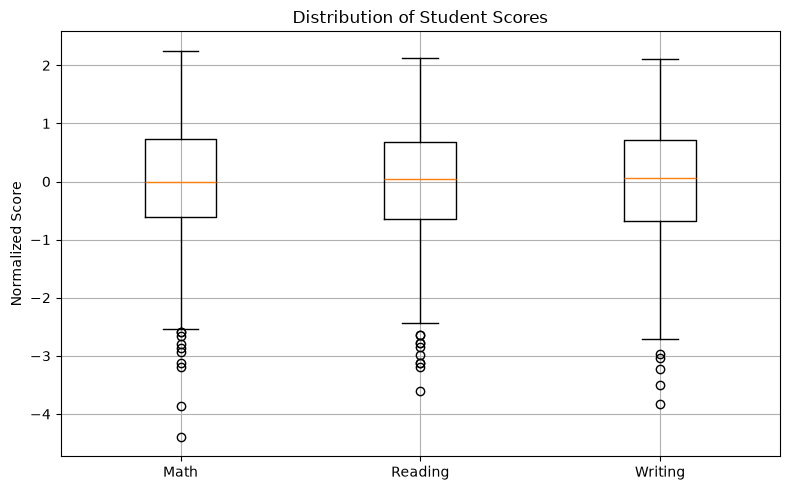

In [24]:
import pandas as pd
import numpy as np

from sklearn.impute import KNNImputer


def impute_data(df):
    """
    Impute missing values using mean, median, mode and KNN.

    Args:
        df (pd.DataFrame): Input dataset.

    Returns:
        pd.DataFrame: Dataset with imputed values.
    """

    df = df.copy()

    # -----------------------------------
    # 1. MODE for categorical column
    # -----------------------------------

    print("Missing values before imputation:")
    print(df.isnull().sum())

    df["lunch"] = df["lunch"].fillna(
        df["lunch"].mode()[0]
    )

    # -----------------------------------
    # Create some missing numeric values
    # for demonstration
    # -----------------------------------

    df.loc[0:9, "math score"] = np.nan
    df.loc[10:19, "reading score"] = np.nan
    df.loc[20:29, "writing score"] = np.nan

    print("\nMissing values after creating numeric NaN:")
    print(df.isnull().sum())

    # -----------------------------------
    # 2. MEAN
    # -----------------------------------

    df["math score"] = df["math score"].fillna(
        df["math score"].mean()
    )

    # -----------------------------------
    # 3. MEDIAN
    # -----------------------------------

    df["reading score"] = df["reading score"].fillna(
        df["reading score"].median()
    )

    # -----------------------------------
    # 4. KNN
    # -----------------------------------

    numeric_columns = [
        "math score",
        "reading score",
        "writing score"
    ]

    imputer = KNNImputer(n_neighbors=5)

    df[numeric_columns] = imputer.fit_transform(
        df[numeric_columns]
    )

    print("\nMissing values after imputation:")
    print(df.isnull().sum())

    return df


df = impute_data(df)

from sklearn.preprocessing import StandardScaler


def normalize_data(df):
    """
    Normalize numeric data using StandardScaler (z-score normalization).

    Args:
        df (pd.DataFrame): The dataset as a pandas DataFrame.

    Returns:
        pd.DataFrame: The dataset with normalized values.
    """

    df = df.copy()

    numeric_columns = [
        "math score",
        "reading score",
        "writing score"
    ]

    scaler = StandardScaler()

    df[numeric_columns] = scaler.fit_transform(
        df[numeric_columns]
    )

    return df


df = normalize_data(df)

print(df.head())

print("\nMean values after normalization:")
print(df[["math score", "reading score", "writing score"]].mean())

print("\nStandard deviation after normalization:")
print(df[["math score", "reading score", "writing score"]].std())

import matplotlib.pyplot as plt


def visualize_data(df):
    """
    Visualize the dataset using Matplotlib.
    Save more than one visualization.

    Args:
        df (pd.DataFrame): The dataset as a pandas DataFrame.

    Returns:
        None
    """

    # -----------------------------------
    # 1. Histogram of math scores
    # -----------------------------------
    plt.figure(figsize=(8, 5))

    plt.hist(
        df["math score"],
        bins=20
    )

    plt.title("Distribution of Math Scores")
    plt.xlabel("Normalized Math Score")
    plt.ylabel("Frequency")
    plt.grid()

    plt.tight_layout()
    plt.savefig("math_score_histogram.png")
    plt.show()
    plt.close()

    # -----------------------------------
    # 2. Reading score vs Writing score
    # -----------------------------------
    plt.figure(figsize=(8, 5))

    plt.scatter(
        df["reading score"],
        df["writing score"],
        alpha=0.5
    )

    plt.title("Reading Score vs Writing Score")
    plt.xlabel("Normalized Reading Score")
    plt.ylabel("Normalized Writing Score")
    plt.grid()

    plt.tight_layout()
    plt.savefig("reading_vs_writing.png")
    plt.show()
    plt.close()

    # -----------------------------------
    # 3. Boxplot of all numeric scores
    # -----------------------------------
    plt.figure(figsize=(8, 5))

    plt.boxplot(
        [
            df["math score"],
            df["reading score"],
            df["writing score"]
        ],
        tick_labels=[
            "Math",
            "Reading",
            "Writing"
        ]
    )

    plt.title("Distribution of Student Scores")
    plt.ylabel("Normalized Score")
    plt.grid()

    plt.tight_layout()
    plt.savefig("scores_boxplot.png")
    plt.show()
    plt.close()


visualize_data(df)